#### Imports

In [233]:
#firstly we will import all the libraries that will be used in this specific question experiment
import numpy as np
import time
import pandas as pd
import matplotlib.pyplot as plt
#k-means clustering libaray import
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_kddcup99 #importing the kddcup99 dataset from the given scikit-learn library


#### Experiment settings

In [234]:
# next we will define the global constants which will be used thoughout this experiment
K=15 #number of clusters to be formed using the k means algo, this was memtioned in the assigment also
N_INIT=5 #number of times k-means will be run with different centroid seeds, the final results will be the best output of n_init consecutive runs in terms of inertia, this is also assignment mentioned
MS=[5,10,15,20,25] # these are the different target projected dimensions that will be tested
REPETITIONS=5 # no. of repeats for each value of target projected dimension, this is to get a more robust result and avoid any bias in the results
N_PAIRS =10_000 # no. of random points pairs to be generated for (e)(i)
N_DRAWS_E=20  # no. of random projetion matrices to be generated for (e)(ii)
SEED=2023146 #set for reproducibility of the result

rng=np.random.default_rng(SEED)# a random number generator using our own seed

#### Plot settings

In [235]:
C1,C2="#2a78d6", "#eb6834"  # plot colours
plt.rcParams.update({"figure.dpi": 110,"axes.grid": True,"grid.alpha": 0.3,"axes.spines.top": False,"axes.spines.right": False})

## Data Preprocessing: building $D$

Steps (i) to (iii) of the question:

1. one-hot encode `protocol_type`, `service` and `flag`, and convert the other 38 features to float;
2. drop every column that is constant over all rows;
3. min-max rescale each remaining column to $[0,1]$.

#### Load connections

In [236]:
# loading the kdd cup 1999 dataset at first
kdd =fetch_kddcup99(subset=None,as_frame=True)
raw=kdd.data.copy() # just creating a copy so that we can manipulate the data without changing the original dataset, this and the previous statement are taken as it is like mentioned in the assignment


#### Decode labels

In [237]:
#converting the target labels from bytes to string format
labels_true=[]
#we loop through the target labels and convert them into string format
for value in kdd.target:
    # if the value is in bytes we decode it to string
    if isinstance(value,(bytes,bytearray)):
        labels_true.append(value.decode())
    # value is already in string so just add to list
    else:
        labels_true.append(str(value))
labels_true=pd.Series(labels_true) # converting the list to a pandas series



#### Identify feature types

In [238]:
#dealing with categorical and numerical columns, as we know that there are 3 categorical columns and 38 numerical columns in the dataset, we will separate them into two different lists
cat_cols=["protocol_type","service","flag"] #3 categorial columns ot one hot encode based on there values
num_cols=[] # storing all the numerical columns in this list
for col in raw.columns:
    # if not in categorical columns then insert into numerical columns list
    if col not in cat_cols:
        num_cols.append(col)
# checking if the total number of columns is 41 and numerical columns are 38, this is just a sanity check to make sure we have not missed any column
assert len(cat_cols)+len(num_cols)==41
assert len(num_cols)==38



#### Decode categorical values

In [239]:
# first data preprocessing step is to convert all the categorical columns into one hot encoded columns

#convert all categorical columns into normal strings first
for column in cat_cols:
    raw[column]=raw[column].apply(
        lambda value: value.decode() if isinstance(value,(bytes,bytearray)) else str(value)
    )


#### Convert numeric columns

In [240]:
# also convert numerical columns to float like asked
num= raw[num_cols]
#convert to float64
num=num.apply(pd.to_numeric)
num=num.astype(np.float64)


#### One-hot encode and combine features

In [241]:
# one hot encode the categorical columns
onehot=pd.get_dummies(
    raw[cat_cols],
    prefix=cat_cols,
    prefix_sep="=",
    dtype=np.float64
    )
# combine the numerical and one hot encoded categorial columns into a single dataframe
full=pd.concat([num, onehot], axis=1)
# Display some information after one-hot encoding
print("Number of columns after one-hot encoding:",full.shape[1])
print("Original numerical columns:",len(num_cols))
print("New one-hot encoded columns:",onehot.shape[1])
for column in cat_cols:
    print(column,"contains",raw[column].nunique(),"unique values")



Number of columns after one-hot encoding: 118
Original numerical columns: 38
New one-hot encoded columns: 80
protocol_type contains 3 unique values
service contains 66 unique values
flag contains 11 unique values


#### Drop constant features

In [242]:
# second data preprocessing step is to drop constant columns, as they do not provide any useful information for clustering
constant_columns=[]
for column in full.columns:
    #check if the column has only one unique value then we need to remove this column because every row has the same value for this, so drop it
    if(full[column].nunique(dropna=False)==1):
        constant_columns.append(column)
full=full.drop(columns=constant_columns)
print("dropped constant columns:",constant_columns)



dropped constant columns: ['num_outbound_cmds', 'is_host_login']


#### Scale features

In [243]:
#the third and final data preprocessing step is to normalize the data, we will use min-max normalization to scale the data between 0 and 1, this is important because k-means is sensitive to the scale of the data
minimum_values=full.min()
maximum_values=full.max()
assert (maximum_values>minimum_values).all() # sanity check to make sure that the max is greater than min for all columns
normalized_data= (full-minimum_values)/(maximum_values-minimum_values)
D=normalized_data.to_numpy(dtype=np.float32) # converting the normalized dataframe to a numpy array of type float32 for efficient computation
feature_names=full.columns.tolist()
#freeing up memory by deleting the intermediate dataframes and series that are no longer needed
del full
del num
del onehot
del normalized_data



#### Verify the resulting matrix

In [244]:
n=D.shape[0]
d=D.shape[1]
#checks
assert np.isfinite(D).all()
assert D.min() >= 0.0
assert D.max() <= 1.0
print("Number of rows (n):",n)
print("Number of columns (d):",d)

print("Distinct rows:",np.unique(D,axis=0).shape[0])
print("Distinct labels:",labels_true.nunique())

Number of rows (n): 494021
Number of columns (d): 116
Distinct rows: 145584
Distinct labels: 23


### Q1 

### Helper functions

* `cost_to_centres(X, B)` gives $\mathrm{cost}(X,B)=\sum_i \min_{b\in B}\lVert X_i-b\rVert_2^2$. Each row goes to its nearest centre. The work is done in chunks using $\lVert x-b\rVert^2=\lVert x\rVert^2-2x^\top b+\lVert b\rVert^2$.
* `cluster_means(X, labels)` gives the means $\mu_j(X)$ of a partition.
* `partition_cost(X, labels)` gives $\mathrm{cost}_X(\mathcal C)=\sum_j\sum_{i\in C_j}\lVert X_i-\mu_j(X)\rVert_2^2$. Each row is measured against the mean of **its own** cluster, so there is no reassignment.

#### Batch size

In [245]:
# Since the dataset is large, we process it in smaller chunks
# to avoid using too much memory at once.
CHUNK=50000



#### Nearest-centre cost

In [246]:
# this funcction will compute the k-means clustering cost, for every data point, it will find the nearest cluster centre and add the squared Euclidean distance, this is done in chunks to avoid memory issues
def cost_to_centres(X,centres,chunk_size=CHUNK):
    # Converting the centres to float64 for better numerical accuracy
    centres=np.asarray(centres, dtype=np.float64)
    # Compute squared norm of every centre
    centre_norms=(centres*centres).sum(axis=1)

    total_cost = 0.0
    # Process the dataset in chunks
    for start in range(0, X.shape[0],chunk_size):
        end=start + chunk_size
        # this will convert the current chunk of data to float64 for better numerical accuracy
        current_chunk=X[start:end].astype(np.float64)
        # Compute squared distance between every point
        # and every cluster centre
        distances=(
            (current_chunk * current_chunk).sum(axis=1)[:, None]
            -2*current_chunk @ centres.T
            +centre_norms[None, :]
        )
        # Distance should never be negative because of
        # floating point errors
        minimum_distance = np.maximum(distances.min(axis=1), 0.0)

        total_cost=total_cost+minimum_distance.sum()
    return total_cost



#### Cluster means

In [247]:
# with this function we will compute the mean of every cluster, this is done by first counting the number of points in each cluster, then summing the points belonging to each cluster and finally dividing by the number of points to obtain the mean
def cluster_means(X, labels, k=K):
    # Count the number of points in each cluster
    counts=np.bincount(labels, minlength=k)
    # we check if any cluster is empty, if so we raise an error, this is important because if a cluster is empty then we cannot compute the mean for that cluster
    if (counts == 0).any():
        empty_clusters = np.where(counts == 0)[0]
        raise ValueError(
            f"Empty clusters found:{empty_clusters}"
        )
    # Storing the sum of all points belonging to each cluster
    sums=np.zeros((k, X.shape[1]))
    # Processing the dataset in chunks to avoid memory issues and add the points to their respective cluster sums
    for start in range(0, X.shape[0], CHUNK):
        end =start+CHUNK
        current_points=X[start:end].astype(np.float64) # converting the current chunk of data to float64 for better numerical accuracy
        current_labels=labels[start:end]# adding the points to their respective cluster sums using numpy's advanced indexing, this is done by using np.add.at which allows us to add the points to the sums array at the indices specified by current_labels
        np.add.at(sums,current_labels,current_points)
    # Dividing by the number of points to obtain the mean
    means = sums/counts[:,None]
    return means



#### Fixed-partition cost

In [248]:
#this function will compute the clustering cost using a fixed partition, it will first compute the cluster means and then for every data point, it will find the nearest cluster centre and add the squared Euclidean distance, this is done in chunks to avoid memory issues
def partition_cost(X, labels, k=K):
    # Compute cluster centres
    means=cluster_means(X,labels,k)
    accumulative_cost=0.0
    # Process data in chunks step by step
    for start in range(0, X.shape[0], CHUNK):
        end=start +CHUNK
        current_points=X[start:end].astype(np.float64)
        current_labels=labels[start:end]
        # Difference between every point and its cluster centre
        difference = current_points-means[current_labels]
        accumulative_cost=accumulative_cost+(difference*difference).sum() #adding the squared Euclidean distance to the accumulative cost for each chunk of data

    return accumulative_cost



#### Gaussian projection matrix

In [249]:
# with this function we will generate a random Gaussian matrix A, every element is drawn independently from N(0, 1/m), if d is not provided, we will use the number of columns in the dataset
def draw_A(m,d=None):
    # if d is not provided, we will use the number of columns in the dataset
    if d is None:
        d=D.shape[1]
    #here we generate a random gaussian matrix A, every element is drawn independently
    A=rng.normal(
        loc=0.0, # mean of the normal distribution
        scale=1.0/np.sqrt(m),# standard deviation of the normal distribution
        size=(m,d)# size of the matrix A, m rows and d columns
    )
    return A # retyurning the random gaussian matrix A




#### Helper checks

In [250]:
# checks for the helper functions
test_data = np.array(
    [
        [0., 0.],
        [2., 0.],
        [10., 0.],
        [12., 0.]
    ],
    dtype=np.float32
)
test_labels = np.array([0, 0, 1, 1])
test_centres = np.array(
    [
        [1., 0.],
        [11., 0.]
    ]
)
assert np.isclose(
    partition_cost(test_data, test_labels, 2),
    4.0
)
assert np.isclose(
    cost_to_centres(test_data, test_centres),
    4.0
)

## (a) k-means on $D$

#### Fit and time k-means

In [251]:
t0=time.perf_counter() #starting the timer to measure the wall-clock time for the k-means clustering on the original dataset D
km_D=KMeans(n_clusters=K,n_init=N_INIT, random_state=SEED).fit(D) #k-means clustering on the original dataset D, we are using the KMeans class from sklearn with the number of clusters K, number of initializations N_INIT and random state SEED for reproducibility
time_a=time.perf_counter()-t0 #stopping the timer and calculating the wall-clock time taken for the k-means clustering on the original dataset D



#### Evaluate the baseline

In [252]:
# here are the cluster centres, labels and costs for the original dataset D
B=km_D.cluster_centers_          # centres B in R^d
labels_D=km_D.labels_            # clusters C_D
cost_DB=cost_to_centres(D,B) # cost(D, B), needed in (a)
cost_D_CD=partition_cost(D,labels_D)# cost_D(C_D), needed in (e)

print(f"cost(D, B) = {cost_DB:,.2f}")
print(f"KMeans inertia_ = {km_D.inertia_:,.2f}   (sklearn's own value, float32, for comparison)")
print(f"cost_D(C_D) = {cost_D_CD:,.2f}   (same partition, centres replaced by exact means)")
print(f"wall-clock time (a) = {time_a:.2f} s")
print("cluster sizes:", np.sort(np.bincount(labels_D, minlength=K))[::-1])

cost(D, B) = 53,938.04
KMeans inertia_ = 53,932.70   (sklearn's own value, float32, for comparison)
cost_D(C_D) = 53,937.96   (same partition, centres replaced by exact means)
wall-clock time (a) = 12.52 s
cluster sizes: [280781  86927  30318  28436  21385   8476   6243   5628   5420   5326
   4577   4278   2828   1862   1536]


## (b), (c), (d) k-means on $E=DA^\top$

For each $m$ and each of the 5 repetitions:

1. draw a fresh $A$;
2. time the computation of $E=DA^\top$ together with k-means on $E$, which is (d);
3. form $\hat B$ by averaging the **original** rows of $D$ in each cluster of $\mathcal C_E$, then compute $\mathrm{cost}(D,\hat B)$, which is (b);
4. map the centres found on $E$ back to $\mathbb R^d$ as $B^+=\{A^+a\}$ with `numpy.linalg.pinv` and compute $\mathrm{cost}(D,B^+)$, which is (c).

The timed region covers only what (d) asks for. Drawing $A$ and evaluating the costs are outside it.

In [253]:
results=[] # this list will store the results of every experiment
# trying every projection dimension as listed in the assignment
# m will take value 5, 10, 15, 20, 25 and for each value of m we will repeat the experiment REPETITIONS times to get a more robust result and avoid any bias in the results
for m in MS:
    print(f"\nRunning for projected dimension m={m}")
    #repeating each experiment multiple (5) times beacause the random projection matrix a, is generated everytime randomly
    for repetition in range(REPETITIONS):
        A=draw_A(m,d) # firstly we generate a random Gaussian matrix A of size m x d, where m is the projected dimension and d is the original dimension of the dataset D
        A_float32=A.astype(np.float32) # converting the random Gaussian matrix A to float32 for efficient computation
        # next step is to project teh original data
        start_time=time.perf_counter()
        E=D@A_float32.T  # this is the projected data, where every row i of E is A D_i, this is done by matrix multiplication of the original data D with the transpose of the random Gaussian matrix A
        # now we will run k-means clustering on the projected data E, we are using
        kmeans_projected=KMeans(
            n_clusters=K,
            n_init=N_INIT,
            random_state=SEED+100*m+repetition
            )
        kmeans_projected.fit(E) # fitting the k-means clustering on the projected data E
        end_time = time.perf_counter()
        exec_time= end_time-start_time # calculating the wall-clock time taken for the k-means clustering on the projected data E

        # next we recover the centers by averaging the original data points that belong to each cluster, this is done by using the labels obtained from the k-means clustering on the projected data E
        labels_E=kmeans_projected.labels_ # labels of the projected data E, this is used to recover the original cluster centres by averaging the original data points that belong to each cluster
        B_hat=cluster_means(D, labels_E)                    # (b): average original rows
        cost_hat=cost_to_centres(D, B_hat)
        ratio_hat=cost_hat/cost_DB # ratio of cost_hat to cost_DB, this is used to compare the cost of the recovered centres with the cost of the original centres

        # recover centers using the pseudo-inverse of A, this is done by multiplying the cluster centres obtained from the k-means clustering on the projected data E with the pseudo-inverse of the random Gaussian matrix A, this will give us an estimate of the original cluster centres in the original space
        pseudo_inverse_A = np.linalg.pinv(A) # computing the pseudo-inverse of the random Gaussian matrix A
        projected_centres = kmeans_projected.cluster_centers_.astype(np.float64) # converting the cluster centres obtained from the k-means clustering on the projected data E to float64 for better numerical accuracy
        B_plus =projected_centres @ pseudo_inverse_A.T   # (c): A^+ a
        cost_plus=cost_to_centres(D,B_plus)
        ratio_plus=cost_plus/cost_DB # ratio of cost_plus to cost_DB, this is used to compare the cost of the recovered centres with the cost of the original centres
        # finally we will store the results
        experiment_result = {
            "m": m,
            "rep": repetition,
            "cost_hat": cost_hat,
            "ratio_hat": ratio_hat,
            "cost_plus": cost_plus,
            "ratio_plus": ratio_plus,
            "time": exec_time,
            "nB_hat": np.linalg.norm(B_hat, axis=1).mean(),
            "nB_plus": np.linalg.norm(B_plus, axis=1).mean()
        }
        results.append(experiment_result)
        print(
            f"m = {m:2d} | "
            f"Run = {repetition + 1} | "
            f"Ratio (B_hat) = {ratio_hat:.4f} | "
            f"Ratio (B_plus) = {ratio_plus:.4f} | "
            f"Time = {exec_time:.2f} seconds"
        )
    del E #free

# Converting collected results into a DataFrame
res = pd.DataFrame(results)


Running for projected dimension m=5
m =  5 | Run = 1 | Ratio (B_hat) = 1.2152 | Ratio (B_plus) = 79.1911 | Time = 2.35 seconds
m =  5 | Run = 2 | Ratio (B_hat) = 1.0807 | Ratio (B_plus) = 79.8863 | Time = 2.34 seconds
m =  5 | Run = 3 | Ratio (B_hat) = 1.0962 | Ratio (B_plus) = 79.5717 | Time = 2.40 seconds
m =  5 | Run = 4 | Ratio (B_hat) = 1.3438 | Ratio (B_plus) = 77.6873 | Time = 2.46 seconds
m =  5 | Run = 5 | Ratio (B_hat) = 1.1497 | Ratio (B_plus) = 78.0839 | Time = 2.38 seconds

Running for projected dimension m=10
m = 10 | Run = 1 | Ratio (B_hat) = 1.0636 | Ratio (B_plus) = 69.4648 | Time = 2.61 seconds
m = 10 | Run = 2 | Ratio (B_hat) = 1.0157 | Ratio (B_plus) = 76.7892 | Time = 2.41 seconds
m = 10 | Run = 3 | Ratio (B_hat) = 1.0565 | Ratio (B_plus) = 78.9793 | Time = 2.65 seconds
m = 10 | Run = 4 | Ratio (B_hat) = 1.0246 | Ratio (B_plus) = 77.1173 | Time = 2.36 seconds
m = 10 | Run = 5 | Ratio (B_hat) = 1.1218 | Ratio (B_plus) = 72.8240 | Time = 2.42 seconds

Running for pr

### (b) Table of $\mathrm{cost}(D,\hat B)/\mathrm{cost}(D,B)$, with (c) alongside

In [254]:
# creating a summary of all the experiments conducted above
# here we are grouping the results acc to the projected dimension(m) and comupte the stats like asked in the assignment mentioned in it
summary=res.groupby("m").agg(
    mean_cost_hat=("cost_hat","mean"), #average clustering cost using B hat
     # Statistics for the cost ratio using B_hat
    ratio_hat_mean=("ratio_hat","mean"),
    ratio_hat_min=("ratio_hat","min"),
    ratio_hat_max=("ratio_hat", "max"),
    # Statistics for the cost ratio using B_plus
    ratio_plus_mean=("ratio_plus", "mean"),

    ratio_plus_min=("ratio_plus","min"),
    ratio_plus_max=("ratio_plus","max"),
    # avg execurion time
    mean_time_s=("time", "mean"))

print(f"cost(D, B) from (a) = {cost_DB:,.2f}\n")
with pd.option_context("display.float_format", "{:,.4f}".format,"display.width", 200):
    display(summary)

print("\nAll 25 runs are as follows:")
with pd.option_context("display.float_format", "{:,.4f}".format,"display.width", 200):
    display(res[["m", "rep", "cost_hat","ratio_hat","cost_plus","ratio_plus","time"]])

cost(D, B) from (a) = 53,938.04



,mean_cost_hat,ratio_hat_mean,ratio_hat_min,ratio_hat_max,ratio_plus_mean,ratio_plus_min,ratio_plus_max,mean_time_s
m,,,,,,,,
5,"63,492.3888",1.1771,1.0807,1.3438,78.8841,77.6873,79.8863,2.3871
10,"56,981.4250",1.0564,1.0157,1.1218,75.0350,69.4648,78.9793,2.4889
15,"56,789.4409",1.0529,0.9603,1.1104,72.7224,67.0391,75.5256,2.7755
20,"55,787.2006",1.0343,1.0172,1.0659,69.3476,64.2974,75.1795,3.0202
25,"54,907.7909",1.0180,0.9815,1.0380,66.6070,64.6792,68.0441,3.2157



All 25 runs are as follows:


,m,rep,cost_hat,ratio_hat,cost_plus,ratio_plus,time
0,5,0,"65,546.4353",1.2152,"4,271,415.0018",79.1911,2.3474
1,5,1,"58,290.2941",1.0807,"4,308,911.0992",79.8863,2.3444
2,5,2,"59,127.0065",1.0962,"4,291,942.2844",79.5717,2.4040
3,5,3,"72,484.1674",1.3438,"4,190,303.5788",77.6873,2.4622
4,5,4,"62,014.0406",1.1497,"4,211,690.4141",78.0839,2.3773
5,10,0,"57,370.5598",1.0636,"3,746,796.8348",69.4648,2.6066
6,10,1,"54,785.0222",1.0157,"4,141,861.4748",76.7892,2.4135
7,10,2,"56,983.5029",1.0565,"4,259,991.3279",78.9793,2.6487
8,10,3,"55,262.8520",1.0246,"4,159,558.0794",77.1173,2.3597
9,10,4,"60,505.1882",1.1218,"3,927,984.8432",72.8240,2.4161


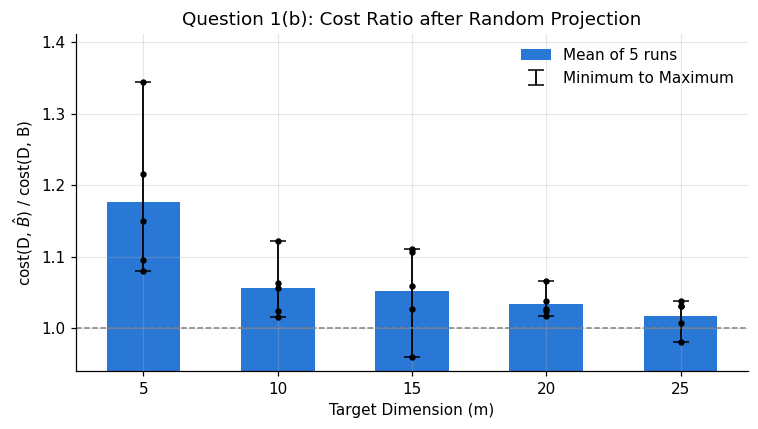

In [255]:
# Creating a figure and axis for the plot
figure,axis=plt.subplots(figsize=(7, 4))
plot_data=summary
# X-axis labels (projection dimensions)
x_labels = [str(value) for value in MS]
# Mean cost ratio for every value of m
mean_ratios = plot_data["ratio_hat_mean"]
# Plotting the average ratio as a bar chart
axis.bar(
    x_labels,
    mean_ratios,
    color=C1,
    width=0.55,
    label="Mean of 5 runs"
)
lower_error=mean_ratios - plot_data["ratio_hat_min"] # here we are computing the error bars
upper_error=plot_data["ratio_hat_max"]-mean_ratios

# Add error bars showing minimum and maximum values
axis.errorbar(
    x_labels,
    mean_ratios,
    yerr=[lower_error, upper_error],
    fmt="none",
    ecolor="black",
    capsize=5,
    linewidth=1.2,
    label="Minimum to Maximum"
)

# Plot every individual experiment as a small black dot
for index, m in enumerate(MS):
    current_values = res.loc[res["m"] == m, "ratio_hat"]
    axis.scatter(
        [index]*REPETITIONS,
        current_values,
        color="black",
        s=10,
        zorder=3
    )
# Draw a horizontal reference line at ratio = 1
axis.axhline(
    y=1.0,
    color="grey",
    linestyle="--",
    linewidth=1
)
# Set suitable limits for the y-axis
minimum_value=min(
    0.95,plot_data["ratio_hat_min"].min() - 0.02
)
maximum_value=plot_data["ratio_hat_max"].max() * 1.05
axis.set_ylim(minimum_value, maximum_value)
axis.set_xlabel("Target Dimension (m)")
axis.set_ylabel(r"cost(D, $\hat{B}$) / cost(D, B)")
axis.set_title("Question 1(b): Cost Ratio after Random Projection")
axis.legend(frameon=False)
plt.tight_layout()
plt.show()

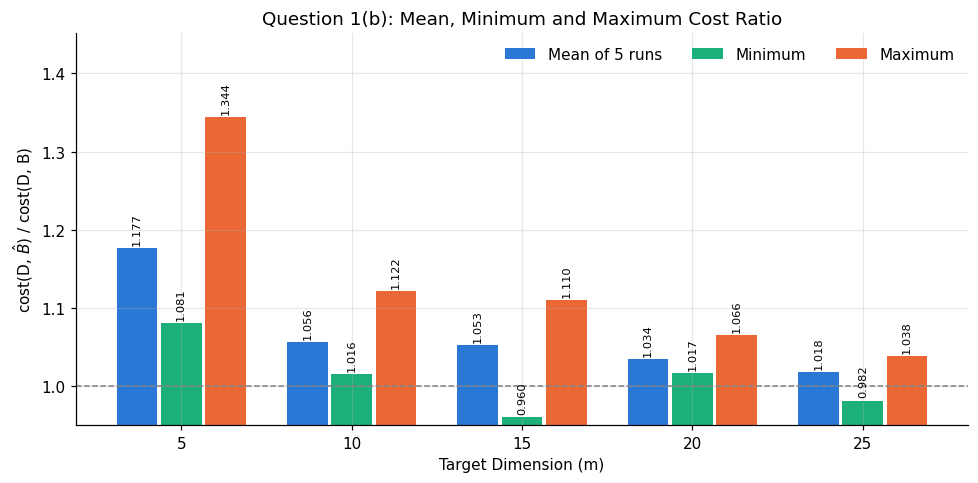

In [256]:
# Q1(b) showing bar graph of the mean, smallest and largest ratio cost(D, B_hat)/cost(D, B) for each m
figure, axis = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(MS))
width = 0.26
bar_stats = [("ratio_hat_mean", "Mean of 5 runs", C1),
             ("ratio_hat_min", "Minimum", "#1baf7a"),
             ("ratio_hat_max", "Maximum", C2)]
for k, (column, label, colour) in enumerate(bar_stats):
    bars = axis.bar(positions + (k - 1) * width, summary[column], width=width * 0.92, color=colour, label=label)
    axis.bar_label(bars, labels=[f"{v:.3f}" for v in summary[column]], padding=2, fontsize=7.5, rotation=90)
axis.axhline(y=1.0, color="grey", linestyle="--", linewidth=1)
axis.set_xticks(positions, [str(m) for m in MS])
axis.set_ylim(0.95, summary["ratio_hat_max"].max() * 1.08)
axis.set_xlabel("Target Dimension (m)")
axis.set_ylabel(r"cost(D, $\hat{B}$) / cost(D, B)")
axis.set_title("Question 1(b): Mean, Minimum and Maximum Cost Ratio")
axis.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

In [257]:
# displaying a short summary of the experimental results
mean_ratios=summary["ratio_hat_mean"] # extracting the avg cost ratios for every value of the target dimension m
below=res[res.ratio_hat<1] #finding all experiments where this ratiois less than 1
print("mean ratio by m:", {m: round(v, 4) for m, v in mean_ratios.items()})
print(f"mean ratio moves from {mean_ratios.iloc[0]:.4f} at m={MS[0]} to {mean_ratios.iloc[-1]:.4f} at m={MS[-1]}; "
      f"spread (max-min) from {summary.ratio_hat_max.iloc[0]-summary.ratio_hat_min.iloc[0]:.4f} "
      f"to {summary.ratio_hat_max.iloc[-1]-summary.ratio_hat_min.iloc[-1]:.4f}")


print(f"runs with ratio < 1: {len(below)} of {len(res)}")
if len(below):
    display(below[["m","rep","cost_hat","ratio_hat"]])

mean ratio by m: {5: 1.1771, 10: 1.0564, 15: 1.0529, 20: 1.0343, 25: 1.018}
mean ratio moves from 1.1771 at m=5 to 1.0180 at m=25; spread (max-min) from 0.2632 to 0.0564
runs with ratio < 1: 2 of 25


,m,rep,cost_hat,ratio_hat
11,15,1,51796.550419,0.960297
23,25,3,52942.500717,0.981543


## (c) Centres mapped back with the pseudo-inverse: $B^+=\{A^+a\}$

In the same 25 runs, the centres found on $E$ are mapped back with `numpy.linalg.pinv` and $\mathrm{cost}(D,B^+)/\mathrm{cost}(D,B)$ is shown next to the ratio from (b). One extra run checks numerically how $B^+$ relates to $\hat B$.

#### Compare centre estimates

In [258]:
# compairing the performance of b hat and b plus
# displaying the summary table and avg norms of b hat and b plus
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(summary[["ratio_hat_mean", "ratio_hat_min", "ratio_hat_max",
                  "ratio_plus_mean", "ratio_plus_min", "ratio_plus_max"]])
    display(res.groupby("m")[["nB_hat", "nB_plus"]].mean().assign(norm_ratio=lambda t: t.nB_plus / t.nB_hat, sqrt_m_over_d=lambda t: np.sqrt(t.index / d)))



,ratio_hat_mean,ratio_hat_min,ratio_hat_max,ratio_plus_mean,ratio_plus_min,ratio_plus_max
m,,,,,,
5,1.1771,1.0807,1.3438,78.8841,77.6873,79.8863
10,1.0564,1.0157,1.1218,75.0350,69.4648,78.9793
15,1.0529,0.9603,1.1104,72.7224,67.0391,75.5256
20,1.0343,1.0172,1.0659,69.3476,64.2974,75.1795
25,1.0180,0.9815,1.0380,66.6070,64.6792,68.0441


,nB_hat,nB_plus,norm_ratio,sqrt_m_over_d
m,,,,
5,2.5953,0.4974,0.1917,0.2076
10,2.6052,0.7591,0.2914,0.2936
15,2.6497,0.9254,0.3493,0.3596
20,2.6492,1.0860,0.4099,0.4152
25,2.6131,1.1978,0.4584,0.4642


#### Check the projection identity

In [259]:
# verifying the relationship between B hat and B plus
A=draw_A(10,d) #generate a random projection matrix
E=D@A.astype(np.float32).T # projecting the original data
# running k means on the projected data
kmeans_E=KMeans(
      n_clusters=K,
      n_init=N_INIT,
      random_state=SEED)
kmeans_E.fit(E)
# recovering the centers by averaging the original points
B_hat=cluster_means(D,kmeans_E.labels_)
P =np.linalg.pinv(A)@A # computing pseudo inverse of A
B_plus =kmeans_E.cluster_centers_.astype(np.float64) @ np.linalg.pinv(A).T # recover centers using pseduo inverse
rel=np.linalg.norm(B_plus - B_hat @ P.T)/np.linalg.norm(B_hat @ P.T)
print(f"relative difference ||B+ - P B_hat|| / ||P B_hat|| = {rel:.2e}  "
"(near 0: the centres on E are the means A b_hat_j, so A^+ a_j = P b_hat_j)")
del E

relative difference ||B+ - P B_hat|| / ||P B_hat|| = 1.77e-04  (near 0: the centres on E are the means A b_hat_j, so A^+ a_j = P b_hat_j)


## (d) Time of computing $E$ plus k-means on $E$

Time of computing $E$ plus k-means on $E$, averaged over the 5 runs for each $m$ and plotted against $m$, with the time from (a) as a horizontal line.

#### Timing table

In [260]:
# here we are computing the running times for different values of m

# Computing the average, minimum and maximum execution timefor every projection dimension.
time_summary=res.groupby("m")["time"].agg(["mean","min","max"])
# showingthe the timing table
display(
    time_summary.style.format("{:.2f}")
)


,mean,min,max
m,,,
5,2.39,2.34,2.46
10,2.49,2.36,2.65
15,2.78,2.65,3.10
20,3.02,2.85,3.13
25,3.22,3.12,3.38


#### Runtime plot

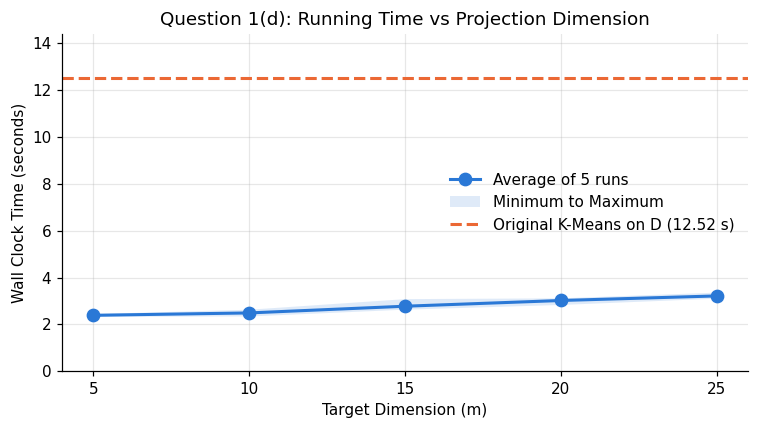

In [261]:
# plotting the run times
#Create a new figure
figure,axis=plt.subplots(figsize=(7, 4))
# Plotting the average running time
axis.plot(
    MS,
    time_summary["mean"],
    marker="o",
    color=C1,
    linewidth=2,
    markersize=8,
    label="Average of 5 runs"
)
# Shading the region between the minimum and maximum time
axis.fill_between(
    MS,
    time_summary["min"],
    time_summary["max"],
    color=C1,
    alpha=0.15,
    linewidth=0,
    label="Minimum to Maximum"
)
# Drawing a horizontal line showing the running time obtained in Q1(a)
axis.axhline(
    y=time_a,
    color=C2,
    linewidth=2,
    linestyle="--",
    label=f"Original K-Means on D ({time_a:.2f} s)"
)
# labeling both the axis
axis.set_xticks(MS)
axis.set_xlabel("Target Dimension (m)")
axis.set_ylabel("Wall Clock Time (seconds)")

# Set the y-axis limit slightly above the largest value
maximum_time=max(time_a,time_summary["max"].max())
axis.set_ylim(0,maximum_time*1.15)
axis.set_title("Question 1(d): Running Time vs Projection Dimension")
axis.legend(frameon=False)

plt.tight_layout()
plt.show()


#### Speedup by dimension

In [262]:
#displaying the speedup over the baseline work in part a
print("Speed-up compared to running K-Means on the original dataset:")
for m in MS:
  average_time=time_summary.loc[m, "mean"]
  speedup = time_a/average_time
  print(f"m = {m} : {speedup:.1f}x")

Speed-up compared to running K-Means on the original dataset:
m = 5 : 5.2x
m = 10 : 5.0x
m = 15 : 4.5x
m = 20 : 4.1x
m = 25 : 3.9x


## (e) Distortion of single pairs against distortion of a whole clustering cost

* (i) Draw $10^4$ random pairs $(i,l)$ with $D_i\ne D_l$ (as vectors, not only $i\ne l$, because KDD99 has many duplicate rows). The same pairs are used for every $m$. For one draw of $A$ per $m$, compute $\lVert E_i-E_l\rVert^2/\lVert D_i-D_l\rVert^2$.
* (ii) For 20 independent draws of $A$ per $m$, compute $\mathrm{cost}_E(\mathcal C_D)/\mathrm{cost}_D(\mathcal C_D)$, where $\mathcal C_D$ is the partition from (a), held fixed.

#### Select nonidentical pairs

In [263]:
#Q1-e part 1
# selecting 10k random pairs of different points
#creating a seperate random number generator
pair_rng=np.random.default_rng(SEED+1)
# lists for storing the selected pairs
I=[]
L=[]
# continuing until we have 10k valid pairs
while (len(I)<N_PAIRS):
    first_indices= pair_rng.integers(
        low=0,
        high=n,
        size=2*N_PAIRS
    )
    second_indices=pair_rng.integers(
        low=0,
        high=n,
        size=2*N_PAIRS
    )
    # igonre the pairs where both indices are the same
    different_indices= (first_indices!=second_indices)
    different_points=(
        np.abs(D[first_indices]-D[second_indices])
    ).sum(axis=1) >0
    valid_pairs=different_indices&different_points # a valid pair must staisfy both the conditions
    # storing the validpairs
    I.extend(first_indices[valid_pairs])
    L.extend(second_indices[valid_pairs])
# Keeping only the first 10,000 pairs
I =np.array(I[:N_PAIRS])
L=np.array(L[:N_PAIRS])
# computing distances in the original space
diff = D[I].astype(np.float64)-D[L].astype(np.float64)
dist_D = (diff ** 2).sum(1)
assert (dist_D>0).all()



#### Measure pairwise distortion

In [264]:
# computing the distance ratios after projection
pair_ratios={}
for m in MS:
    A =draw_A(m,d) #generating  random projection matrix
    E_pairs=diff@A.T#project only the difference vectors, E_i - E_l = A (D_i - D_l)
    pair_ratios[m]=(E_pairs ** 2).sum(1)/dist_D



#### Measure fixed-partition distortion

In [265]:
#q1-e part 2
cost_ratios = {}
# try for every projected target dimesnison
for m in MS:
    ratios = []
    # Repeating the experiment 20 times
    for draw in range(N_DRAWS_E):
        # Generating a new projection matrix
        A=draw_A(m, d)
        # first Project the entire dataset
        projected_data =D@A.astype(np.float32).T
        # then Compute the partition cost
        projected_cost=partition_cost(projected_data,labels_D)
        ratio = projected_cost/cost_D_CD
        ratios.append(ratio)
    cost_ratios[m]=np.array(ratios)
# Free
del projected_data

#### Compute scatter and effective rank

In [266]:
# compairing the theoretial and the experimental spread
# computing the cluster means using the original dataset
cluster_centers =cluster_means(D,labels_D)
G= np.zeros((d,d)) # the matrix G stores teh covairiance like information of the residual vectors
for start in range(0,n,CHUNK):
    end=start+CHUNK
    current_points=D[start:end].astype(np.float64)
    current_labels=labels_D[start:end]
    # the residual vectors
    residuals=current_points-cluster_centers[current_labels]
    G=G+residuals.T @residuals # update the G
# computing the effective rank once G is complete
trace_G =np.trace(G)
frobenius_norm_squared=(G**2).sum()
effective_rank=(trace_G**2)/frobenius_norm_squared
print(f"Trace(G): {trace_G:,.2f}")
print(f"Cost_D(C_D): {cost_D_CD:,.2f}")
print(f"Effective Rank: {effective_rank:.2f}")
print()



Trace(G): 53,937.96
Cost_D(C_D): 53,937.96
Effective Rank: 15.87



#### Summarize measured and theoretical spread

In [267]:
tab=pd.DataFrame({
    "pairs: mean": [pair_ratios[m].mean() for m in MS],
    "pairs: sd": [pair_ratios[m].std(ddof=1) for m in MS],
    "pairs: sd theory": [np.sqrt(2 / m) for m in MS],
    "pairs: IQR": [np.subtract(*np.percentile(pair_ratios[m], [75, 25])) for m in MS],
    "pairs: min": [pair_ratios[m].min() for m in MS],
    "pairs: max": [pair_ratios[m].max() for m in MS],
    "cost: mean": [cost_ratios[m].mean() for m in MS],
    "cost: sd": [cost_ratios[m].std(ddof=1) for m in MS],
    "cost: sd theory": [np.sqrt(2/m/effective_rank) for m in MS],
    "cost: IQR": [np.subtract(*np.percentile(cost_ratios[m], [75, 25])) for m in MS],
    "cost: min": [cost_ratios[m].min() for m in MS],
    "cost: max": [cost_ratios[m].max() for m in MS],
},index=pd.Index(MS, name="m"))
# displaying the table
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(tab.T)

m,5,10,15,20,25
pairs: mean,1.0641,0.6225,1.1235,1.0840,0.7406
pairs: sd,0.3449,0.2565,0.3501,0.2965,0.2227
pairs: sd theory,0.6325,0.4472,0.3651,0.3162,0.2828
pairs: IQR,0.3557,0.2478,0.4777,0.3796,0.3126
pairs: min,0.0434,0.1051,0.2997,0.2965,0.3468
pairs: max,2.6749,2.5220,2.5571,2.0153,1.7246
cost: mean,1.0319,1.0058,0.9889,1.0035,0.9761
cost: sd,0.1871,0.0983,0.0716,0.1060,0.0668
cost: sd theory,0.1587,0.1122,0.0916,0.0794,0.0710
cost: IQR,0.2933,0.1408,0.0689,0.1286,0.0915


#### Compare both distributions

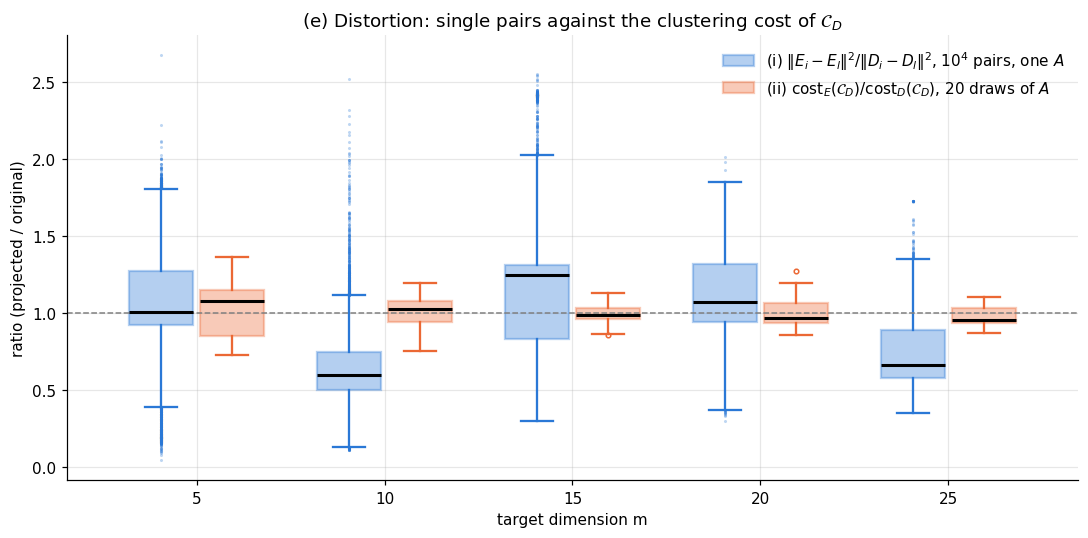

In [268]:

figure, axis = plt.subplots(figsize=(10, 5))
w= 0.34
pos= np.arange(len(MS))
bp1= axis.boxplot([pair_ratios[m] for m in MS], positions=pos - w / 2 - 0.02, widths=w,patch_artist=True, showfliers=True, flierprops=dict(marker=".", ms=2, alpha=0.3, mec=C1))

bp2 = axis.boxplot([cost_ratios[m] for m in MS], positions=pos + w / 2 + 0.02, widths=w,patch_artist=True, showfliers=True, flierprops=dict(marker="o", ms=3, mec=C2))
for bp,c in [(bp1, C1), (bp2, C2)]:
    for b in bp["boxes"]:
        b.set(facecolor=c, alpha=0.35, edgecolor=c, lw=1.5)
    for key in ["whiskers", "caps"]:
        for e in bp[key]:
            e.set(color=c, lw=1.5)
    for e in bp["medians"]:
        e.set(color="black", lw=2)
axis.axhline(1.0, color="grey", ls="--", lw=1)
axis.set_xticks(pos, [str(m) for m in MS])
axis.set_xlabel("target dimension m")
axis.set_ylabel("ratio (projected / original)")
axis.set_title("(e) Distortion: single pairs against the clustering cost of $\\mathcal{C}_D$")
axis.legend([bp1["boxes"][0], bp2["boxes"][0]],
          [r"(i) $\|E_i-E_l\|^2/\|D_i-D_l\|^2$, $10^4$ pairs, one $A$",
           r"(ii) $\mathrm{cost}_E(\mathcal{C}_D)/\mathrm{cost}_D(\mathcal{C}_D)$, 20 draws of $A$"],
          frameon=False, loc="upper right")
plt.tight_layout(); plt.show()



#### **Inspecting for Part (i)**

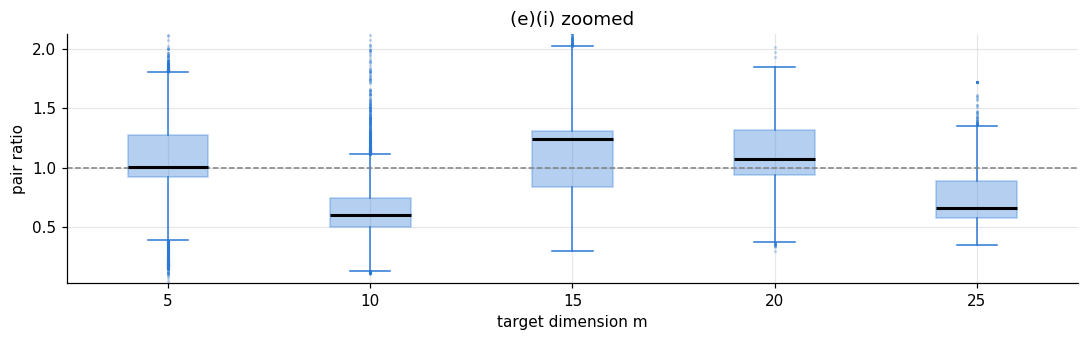

In [269]:
# Q1(e)(i) zoomed: pair ratios only, axis fitted to the boxes and whiskers
figure,axis=plt.subplots(figsize=(10, 3.2))
bp = axis.boxplot([pair_ratios[m] for m in MS], positions=pos, widths=0.4, patch_artist=True,
                boxprops=dict(facecolor=C1, alpha=0.35, edgecolor=C1),
                whiskerprops=dict(color=C1), capprops=dict(color=C1),
                medianprops=dict(color="black", lw=2),
                flierprops=dict(marker=".", ms=2, alpha=0.3, markeredgecolor=C1))
whisker_ends = np.concatenate([w.get_ydata() for w in bp["whiskers"]])
axis.set_ylim(whisker_ends.min() - 0.1, whisker_ends.max() + 0.1)   # outliers beyond the whiskers fall outside this view
axis.axhline(1.0, color="grey", ls="--", lw=1)
axis.set_xticks(pos, [str(m) for m in MS]); axis.set_xlabel("target dimension m")
axis.set_ylabel("pair ratio"); axis.set_title("(e)(i) zoomed")
plt.tight_layout(); plt.show()

#### Inspect fixed-partition costs

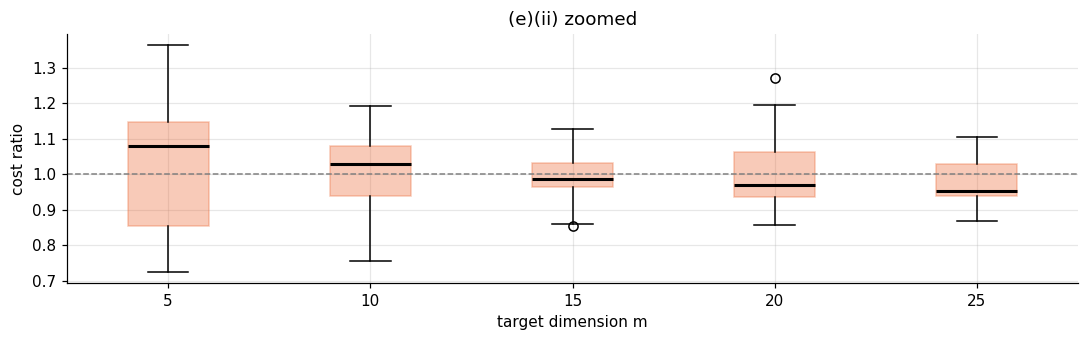

In [270]:
# Same figure,showing zoomed to show the (ii) boxes clearly
figure, axis = plt.subplots(figsize=(10, 3.2))
axis.boxplot([cost_ratios[m] for m in MS], positions=pos, widths=0.4, patch_artist=True,
           boxprops=dict(facecolor=C2, alpha=0.35, edgecolor=C2), medianprops=dict(color="black", lw=2))
axis.axhline(1.0, color="grey", ls="--", lw=1)
axis.set_xticks(pos, [str(m) for m in MS]); axis.set_xlabel("target dimension m")
axis.set_ylabel("cost ratio"); axis.set_title("(e)(ii) zoomed")
plt.tight_layout(); plt.show()

## Summary of reported quantities

In [271]:
# final summary showing all the results for question 1
# Printing the dimensions of the processed dataset
print(f"Number of rows (n): {n}")
print(f"Number of columns (d): {d}")
# Prining t the baseline clustering results from Question 1(a)
print(f"\nCost(D, B): {cost_DB:,.2f}")
print(f"Execution Time: {time_a:.2f} seconds")
# showiing the summary table
# Select only the columns required for the final report
final_summary = summary[
    [
        "mean_cost_hat",
        "ratio_hat_mean",
        "ratio_hat_min",
        "ratio_hat_max",
        "ratio_plus_mean",
        "mean_time_s"
    ]
].copy()
# Rename the columns to make them easier to understand
final_summary.columns = [
    "Mean Cost(D, B̂)",
    "Mean Ratio (B̂)",
    "Minimum Ratio (B̂)",
    "Maximum Ratio (B̂)",
    "Mean Ratio (B⁺)",
    "Mean Time (seconds)"
]
# display the summary table
with pd.option_context(
    "display.float_format", "{:,.4f}".format,
    "display.width", 200
):
    display(final_summary)

Number of rows (n): 494021
Number of columns (d): 116

Cost(D, B): 53,938.04
Execution Time: 12.52 seconds


,"Mean Cost(D, B̂)",Mean Ratio (B̂),Minimum Ratio (B̂),Maximum Ratio (B̂),Mean Ratio (B⁺),Mean Time (seconds)
m,,,,,,
5,"63,492.3888",1.1771,1.0807,1.3438,78.8841,2.3871
10,"56,981.4250",1.0564,1.0157,1.1218,75.0350,2.4889
15,"56,789.4409",1.0529,0.9603,1.1104,72.7224,2.7755
20,"55,787.2006",1.0343,1.0172,1.0659,69.3476,3.0202
25,"54,907.7909",1.0180,0.9815,1.0380,66.6070,3.2157


## Q2

### Regression setup



In [272]:

y = labels_true.ne("normal.").to_numpy(dtype=np.float64)

# Promote the existing scaled values for the numerical rank and least-squares solve.
D_reg = np.asarray(D, dtype=np.float64, order="C")
reg_meta = {"rows": n, "features": d}

### Helper Functions



In [273]:
def sketch(X, target, m):
    """Add each signed feature row and its response to the same random bucket."""
    buckets = rng.integers(m, size=len(X))
    signs = rng.choice([-1.0, 1.0], size=len(X))
    sketch_X = np.zeros((m, X.shape[1]), dtype=np.float64)
    sketch_y = np.zeros(m, dtype=np.float64)

    # Limit the signed-row temporary while accumulating repeated bucket indices.
    for start in range(0, len(X), 8192):
        block = slice(start, start + 8192)
        np.add.at(sketch_X, buckets[block], signs[block, None] * X[block])
        np.add.at(sketch_y, buckets[block], signs[block] * target[block])
    return sketch_X, sketch_y

In [274]:
# Use least squares without an intercept and retain the numerical rank.
def solve(X,target):
    return np.linalg.lstsq(X,target,rcond=None)

# Evaluate the sum of squared residuals on the supplied data.
def loss(X,target,a):
    return np.sum((X@a-target)**2)

## (a) Full least-squares fit

In [275]:
start = time.perf_counter()
b,_,rank,_ = solve(D_reg,y)
reg_meta["reg_time"] = time.perf_counter()-start
reg_meta["rank"] = int(rank)
v = D_reg@b-y
reg_meta["loss"] = v@v
display(pd.Series(reg_meta))

rows        494021.000000
features       116.000000
reg_time         5.589978
rank           113.000000
loss          2949.788815
dtype: float64

## (b) Draw and fit 35 independent sketches

In [276]:
rows = []
for m in (50,100,200,500,1000,2000,5000):
    for trial in range(1, REPETITIONS + 1):
        start = time.perf_counter()
        X,t = sketch(D_reg,y,m)
        a,_,_,_ = solve(X,t)
        seconds = time.perf_counter()-start
        value = loss(D_reg,y,a)
        rows.append((m,trial,value,value/reg_meta["loss"],loss(X,t,a),seconds))

## (b) Report each trial

In [277]:
reg = pd.DataFrame(rows,columns="m trial loss ratio sketch_loss seconds".split())
display(reg)

,m,trial,loss,ratio,sketch_loss,seconds
0,50,1,8465.617585,2.869906,7.318389e-25,0.666682
1,50,2,9196.044330,3.117526,7.711273e-25,0.664470
2,50,3,6868.973090,2.328632,2.500033e-23,0.597742
3,50,4,14550.216079,4.932630,6.276367e-25,0.629128
4,50,5,8297.487267,2.812909,5.886888e-24,0.611593
5,100,1,22207.451795,7.528489,3.932481e-24,0.611708
6,100,2,27931.864396,9.469106,4.538829e-24,0.616071
7,100,3,30978.615859,10.501978,2.622748e-23,0.629912
8,100,4,56462.001474,19.141032,3.464690e-23,0.627928
9,100,5,117942.157532,39.983255,1.185096e-23,0.658277


## (b) Summarize full and sketched losses

`time_over_full` is the mean time to draw the sketch, apply it to the data and target, and solve the sketched problem, divided by the full least-squares solve time from Q2(a). A value of 0.25 means the sketched fit took 25% of the full solve time (4 times as fast).

In [278]:
reg_summary = reg.groupby("m").agg(mean=("ratio","mean"),low=("ratio","min"),high=("ratio","max"),sketched_loss=("sketch_loss","mean"),seconds=("seconds","mean"))
reg_summary["time_over_full"] = reg_summary.seconds/reg_meta["reg_time"]
display(reg_summary)

,mean,low,high,sketched_loss,seconds,time_over_full
m,,,,,,
50,3.212321,2.328632,4.932630,6.603564e-24,0.633923,0.113404
100,17.324772,7.528489,39.983255,1.623933e-23,0.628779,0.112483
200,2.245004,2.071755,2.378901,1.246721e+03,0.658220,0.117750
500,1.275028,1.209216,1.327328,2.344471e+03,0.637362,0.114019
1000,1.141299,1.126961,1.167954,2.664047e+03,0.673027,0.120399
2000,1.060976,1.052906,1.073882,2.768398e+03,0.641996,0.114848
5000,1.023797,1.021758,1.027012,2.849604e+03,0.657584,0.117636


## (b) Plot mean ratio and observed range

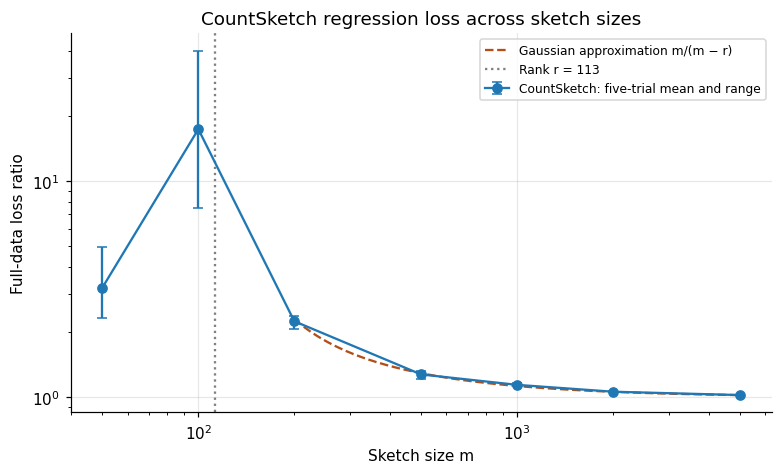

In [279]:
fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.errorbar(reg_summary.index, reg_summary["mean"],
            yerr=[reg_summary["mean"] - reg_summary.low, reg_summary.high - reg_summary["mean"]],
            fmt="o-", capsize=3, label="CountSketch: five-trial mean and range")
# Evaluate the above-rank approximation over the tested above-rank interval.
above_rank = reg_summary.index[reg_summary.index > rank]
m_curve = np.geomspace(above_rank.min(), above_rank.max(), 240)
ax.plot(m_curve, m_curve / (m_curve - rank), "--", color="#b44e18",
        label="Gaussian approximation m/(m − r)")
ax.axvline(rank, color="gray", linestyle=":", label=f"Rank r = {rank}")
ax.set(xscale="log", yscale="log", xlabel="Sketch size m", ylabel="Full-data loss ratio",
       title="CountSketch regression loss across sketch sizes")
ax.legend(fontsize=8)
plt.show()

## (c) Compare mean sketch-and-solve time with the full fit

Sketch seconds are averaged over the five Q2(b) trials. Speedup divides Q2(a) full-solve seconds by mean sketch seconds. Loss increase compares the mean full-data loss of those sketched fits with the optimal full-data loss.

In [280]:
# Each row summarizes the five measured Q2(b) trials at one sketch size.
assert reg.groupby("m").size().eq(REPETITIONS).all()
comparison = reg.groupby("m").agg(
    sketch_seconds=("seconds", "mean"),
    mean_loss_ratio=("ratio", "mean"),
)
comparison["full_seconds"] = reg_meta["reg_time"]
comparison["speedup"] = comparison.full_seconds / comparison.sketch_seconds
comparison["loss_increase_pct"] = 100 * (comparison.mean_loss_ratio - 1)
display(comparison[["sketch_seconds", "full_seconds", "speedup", "loss_increase_pct"]].style.format({
    "sketch_seconds": "{:.3f} s", "full_seconds": "{:.3f} s",
    "speedup": "{:.1f}x", "loss_increase_pct": "{:,.1f}%"
}))

,sketch_seconds,full_seconds,speedup,loss_increase_pct
m,,,,
50,0.634 s,5.590 s,8.8x,221.2%
100,0.629 s,5.590 s,8.9x,"1,632.5%"
200,0.658 s,5.590 s,8.5x,124.5%
500,0.637 s,5.590 s,8.8x,27.5%
1000,0.673 s,5.590 s,8.3x,14.1%
2000,0.642 s,5.590 s,8.7x,6.1%
5000,0.658 s,5.590 s,8.5x,2.4%


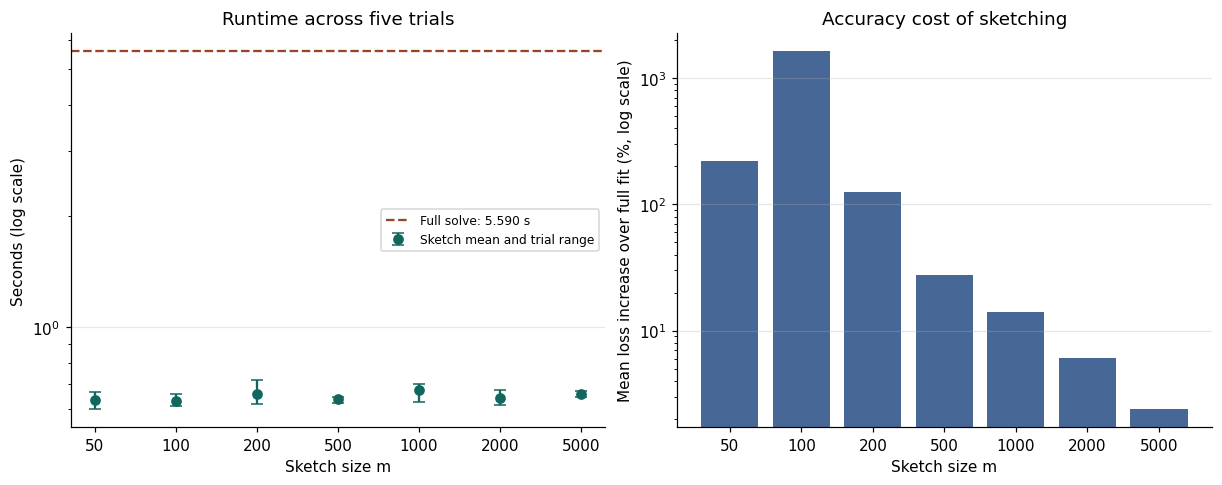

In [281]:
fig, (runtime_ax, loss_ax) = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
positions = np.arange(len(comparison))
times = reg.groupby("m").seconds
runtime_ax.errorbar(positions, comparison.sketch_seconds,
                    yerr=[comparison.sketch_seconds - times.min(), times.max() - comparison.sketch_seconds],
                    fmt="o", color="#11665d", capsize=4, label="Sketch mean and trial range")
runtime_ax.axhline(reg_meta["reg_time"], ls="--", color="#984525",
                   label=f"Full solve: {reg_meta['reg_time']:.3f} s")
runtime_ax.set(yscale="log", ylabel="Seconds (log scale)", title="Runtime across five trials")
runtime_ax.legend(fontsize=8, loc="center right")
loss_ax.bar(positions, comparison.loss_increase_pct, color="#476896")
loss_ax.set(yscale="log", ylabel="Mean loss increase over full fit (%, log scale)",
            title="Accuracy cost of sketching")
for axis in (runtime_ax, loss_ax):
    axis.set_xticks(positions, comparison.index)
    axis.set_xlabel("Sketch size m")
    axis.grid(axis="x", visible=False)
plt.show()

## (d) Sketch the fixed residual 100 times per dimension

In [282]:
rows = []
for m in (50,500,5000):
    for _ in range(100):
        h = rng.integers(m,size=n)
        z = np.bincount(h,weights=v*rng.choice([-1.,1.],size=n),minlength=m)
        rows.append((m,(z@z)/reg_meta["loss"]))

## (d) Report sample means and standard deviations

In [283]:
residual_trials = pd.DataFrame(rows, columns=["m", "ratio"])
spread = residual_trials.groupby("m").ratio.agg(["mean", "std"])
# Compare each sketch size with the preceding size. The first row is the baseline.
spread["size_multiple"] = spread.index.to_series().div(spread.index.to_series().shift())
spread["std_reduction_pct"] = 100 * (1 - spread["std"] / spread["std"].shift())
display(spread.style.format({"mean": "{:.4f}", "std": "{:.4f}",
                             "size_multiple": "{:.0f}x", "std_reduction_pct": "{:.1f}%"}, na_rep="-"))

,mean,std,size_multiple,std_reduction_pct
m,,,,
50,0.9976,0.1896,-,-
500,1.0046,0.0691,10x,63.6%
5000,1.0001,0.0193,10x,72.0%


## (d) Compare the three histograms

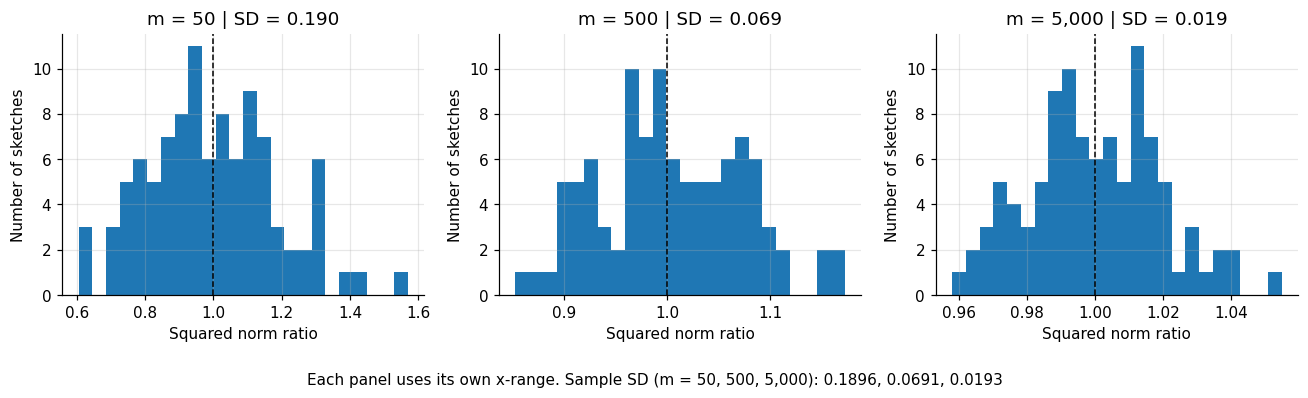

m = 50 to 500 (10x): sample SD falls from 0.1896 to 0.0691, a 63.6% reduction.
m = 500 to 5,000 (10x): sample SD falls from 0.0691 to 0.0193, a 72.0% reduction.
m=50: mean=0.9976, sample SD=0.1896, theoretical SD=0.2000
m=500: mean=1.0046, sample SD=0.0691, theoretical SD=0.0632
m=5000: mean=1.0001, sample SD=0.0193, theoretical SD=0.0200
Expected SD reduction for a tenfold size increase: 68.4%


In [284]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=False, sharey=True)
for ax, (m, group) in zip(axes, residual_trials.groupby("m")):
    ax.hist(group.ratio, bins=24)
    ax.axvline(1, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"m = {m:,} | SD = {spread.loc[m, 'std']:.3f}",
           xlabel="Squared norm ratio", ylabel="Number of sketches")
    ax.tick_params(axis="y", labelleft=True)
caption = "Each panel uses its own x-range. Sample SD (m = 50, 500, 5,000): " + ", ".join(f"{value:.4f}" for value in spread["std"])
fig.text(0.5, 0.015, caption, ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
for previous, current in zip(spread.index, spread.index[1:]):
    print(f"m = {previous:,} to {current:,} ({spread.loc[current, 'size_multiple']:.0f}x): "
          f"sample SD falls from {spread.loc[previous, 'std']:.4f} to "
          f"{spread.loc[current, 'std']:.4f}, a {spread.loc[current, 'std_reduction_pct']:.1f}% reduction.")
# Exact CountSketch SD for this fixed residual vector.
weights = v**2 / (v @ v)
for m, row in spread.iterrows():
    theory_sd = np.sqrt(2 / m * (1 - weights @ weights))
    print(f"m={m}: mean={row['mean']:.4f}, sample SD={row['std']:.4f}, theoretical SD={theory_sd:.4f}")
print(f"Expected SD reduction for a tenfold size increase: {100 * (1 - 1 / np.sqrt(10)):.1f}%")

## (e) Draw one fixed subset and fit its baseline

In [ ]:
# This generator is used only to choose the shared subset for part (e).
SUBSET_SEED = 2023146
subset_rng = np.random.default_rng(SUBSET_SEED)
ids = subset_rng.choice(n, size=50_000, replace=False)
X,t = D_reg[ids], y[ids]
optimal = loss(X,t,solve(X,t)[0])

## (e) Compare five sparse and five dense sketches

In [286]:
rows = []
for method in ("CountSketch","Gaussian"):
    for trial in range(1, REPETITIONS + 1):
        start = time.perf_counter()
        if method == "Gaussian":
            S = draw_A(500,len(X))
            small,response = S@X,S@t
            del S
        else:
            small,response = sketch(X,t,500)
        seconds = time.perf_counter()-start
        a = solve(small,response)[0]
        rows.append((method,trial,seconds,loss(X,t,a)/optimal))

## (e) Individual trials and five-trial means

In [287]:
subset = pd.DataFrame(rows,columns="method trial seconds ratio".split())
print("Individual trials (seconds to construct and apply the sketch; loss relative to the subset optimum)")
display(subset.sort_values(["trial", "method"]).reset_index(drop=True))
print("Mean over five trials per method")
display(subset.groupby("method")[["seconds","ratio"]].mean())

Individual trials (seconds to construct and apply the sketch; loss relative to the subset optimum)


,method,trial,seconds,ratio
0,CountSketch,1,0.064526,1.253451
1,Gaussian,1,0.399178,1.311333
2,CountSketch,2,0.063243,1.228533
3,Gaussian,2,0.397998,1.211376
4,CountSketch,3,0.062864,1.232780
5,Gaussian,3,0.383641,1.297647
6,CountSketch,4,0.061992,1.355398
7,Gaussian,4,0.388412,1.373545
8,CountSketch,5,0.059854,1.250131
9,Gaussian,5,0.393410,1.301642


Mean over five trials per method


,seconds,ratio
method,,
CountSketch,0.062496,1.264058
Gaussian,0.392528,1.299109
